# Map MOI, OMIM disease module to gene and variants

In [1]:
import os
import sys
import pandas as pd

In [38]:
input_dir = '../1_inputs'
output_dir = '../3_outputs'

In [39]:
# This is a local file, not in the repo
allele_collection_df = pd.read_csv('../../../cloned_mutations_101525/ccsb_cloned_mutations_250220.csv', sep='\t')
allele_collection_df

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_15511/151193764.py:2: DtypeWarning: Columns (29) have mixed types. Specify dtype option on import or set low_memory=False.
  allele_collection_df = pd.read_csv('../../../cloned_mutations_101525/ccsb_cloned_mutations_250220.csv', sep='\t')


,mutation_id,orf_id,nt_change,aa_change,cloned,ensembl_protein_id,orf_class,aa_change_hgvs,nt_change_cnt,cloned_project,...,hgmd_clinical_significance,hgmd_phenotype,clinical_significance,category,clinical_significance_simple,strand,in_21,in_phase1,in_georges_1k,in_phase1_cloned
0,CCSBVarC000001,2,160G>C,Val54Leu,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Val54Leu,1,pre_varchamp,...,DM,Gaucher disease,Pathogenic,NaN,Pathogenic,-,1.0,0.0,0.0,0.0
1,CCSBVarC000002,2,670C>T,Leu224Phe,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu224Phe,1,pre_varchamp,...,DM?,Gaucher disease,Pathogenic,NaN,Pathogenic,-,1.0,0.0,0.0,0.0
2,CCSBVarC000003,2,887G>A,Arg296Gln,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Arg296Gln,1,pre_varchamp,...,DM,Gaucher disease,Pathogenic,pathogenic,pathogenic,-,1.0,0.0,0.0,0.0
3,CCSBVarC000004,2,1448T>C,Leu483Pro,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu483Pro,1,pre_varchamp,...,DM,Gaucher disease 2,Conflicting,NaN,Conflicting,-,1.0,0.0,0.0,0.0
4,CCSBVarC000005,25,328C>G,Leu110Val,1,ENSP00000262613.5,class1m,ENSP00000262613.5:p.Leu110Val,1,pre_varchamp,...,DM?,Nephrolithiasis/bone demineralization,Conflicting,NaN,Conflicting,+,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21787,CCSBVarC039842,1460,2671A>G,Ser891Gly,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser891Gly,1,varchamp_pign,...,NaN,NaN,NaN,VUS,VUS,-,NaN,NaN,NaN,NaN
21788,CCSBVarC039843,1460,2699C>G,Ser900Cys,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser900Cys,1,varchamp_pign,...,NaN,NaN,NaN,VUS,VUS,-,NaN,NaN,NaN,NaN
21789,CCSBVarC039844,1460,2701A>G,Met901Val,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Met901Val,1,varchamp_pign,...,NaN,NaN,NaN,VUS,VUS,-,NaN,NaN,NaN,NaN
21790,CCSBVarC039845,1460,2750C>T,Thr917Met,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Thr917Met,1,varchamp_pign,...,NaN,NaN,NaN,VUS,VUS,-,NaN,NaN,NaN,NaN


In [56]:
real_allele_collection_df = pd.read_csv(f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv', sep='\t', low_memory=False)
real_allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710


In [59]:
real_allele_collection_df.collection.value_counts(dropna=False)

collection
CEGS2          4296
RC4            2948
Edgotyping3    1466
NaN             443
Name: count, dtype: int64

In [29]:
# Need to remap from ClinVar

# Load the clinvar gzipped data locally

clinvar_df = pd.read_csv('../../../../ClinVar/March_2025_1perc/variant_summary_2025-03.txt.gz', sep='\t', compression='gzip', low_memory=False)

In [31]:
clinvar_df = clinvar_df[clinvar_df.Assembly == 'GRCh38']

In [32]:
clinvar_df

,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),...,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification
1,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 25, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007,-,-
3,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
5,15043,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,...,A,-,-,-,-,-,-,SCV000020157,-,-
7,15044,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Mar 12, 2024",267606829,...,T,-,-,-,-,-,-,SCV000680696|SCV001363290|SCV002793147|SCV0029...,-,-
9,15045,single nucleotide variant,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),55572,FOXRED1,HGNC:26927,Likely pathogenic,1,"Jun 06, 2024",267606830,...,G,-,-,-,-,-,-,SCV005680614,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6839990,3880932,Deletion,NM_021096.4(CACNA1I):c.3474-2_3476del,8911,CACNA1I,HGNC:1396,Pathogenic,1,"Feb 02, 2024",-1,...,C,-,-,-,-,-,-,SCV005689470,-,-
6839992,3880933,Duplication,NC_000023.11:g.103577174dup,79921,TCEAL4,HGNC:26121,Uncertain significance,0,"Feb 02, 2024",-1,...,AG,-,-,-,-,-,-,SCV005689471,-,-
6839994,3880935,single nucleotide variant,NM_133433.4(NIPBL):c.5524C>T (p.Arg1842Ter),25836,NIPBL,HGNC:28862,Pathogenic,1,"Feb 28, 2025",-1,...,T,-,-,-,-,-,-,SCV005871634,-,-
6839996,3880936,single nucleotide variant,NM_171998.4(RAB39B):c.511A>G (p.Ile171Val),116442,RAB39B,HGNC:16499,Uncertain significance,0,"Feb 28, 2025",-1,...,C,-,-,-,-,-,-,SCV005871635,-,-


In [34]:
clinvar_df['#AlleleID'] = clinvar_df['#AlleleID'].astype(float)
clinvar_df

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_15511/2179972607.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinvar_df['#AlleleID'] = clinvar_df['#AlleleID'].astype(float)


,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),...,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification
1,15041.0,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 25, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007,-,-
3,15042.0,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
5,15043.0,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,...,A,-,-,-,-,-,-,SCV000020157,-,-
7,15044.0,single nucleotide variant,NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter),55572,FOXRED1,HGNC:26927,Pathogenic,1,"Mar 12, 2024",267606829,...,T,-,-,-,-,-,-,SCV000680696|SCV001363290|SCV002793147|SCV0029...,-,-
9,15045.0,single nucleotide variant,NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser),55572,FOXRED1,HGNC:26927,Likely pathogenic,1,"Jun 06, 2024",267606830,...,G,-,-,-,-,-,-,SCV005680614,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6839990,3880932.0,Deletion,NM_021096.4(CACNA1I):c.3474-2_3476del,8911,CACNA1I,HGNC:1396,Pathogenic,1,"Feb 02, 2024",-1,...,C,-,-,-,-,-,-,SCV005689470,-,-
6839992,3880933.0,Duplication,NC_000023.11:g.103577174dup,79921,TCEAL4,HGNC:26121,Uncertain significance,0,"Feb 02, 2024",-1,...,AG,-,-,-,-,-,-,SCV005689471,-,-
6839994,3880935.0,single nucleotide variant,NM_133433.4(NIPBL):c.5524C>T (p.Arg1842Ter),25836,NIPBL,HGNC:28862,Pathogenic,1,"Feb 28, 2025",-1,...,T,-,-,-,-,-,-,SCV005871634,-,-
6839996,3880936.0,single nucleotide variant,NM_171998.4(RAB39B):c.511A>G (p.Ile171Val),116442,RAB39B,HGNC:16499,Uncertain significance,0,"Feb 28, 2025",-1,...,C,-,-,-,-,-,-,SCV005871635,-,-


In [48]:
# Using the AlleleID to map PhenotypeIDS on the allele_collection_df
clinvar_map = clinvar_df[['#AlleleID', 'PhenotypeIDS', 'ClinicalSignificance']].drop_duplicates()
clinvar_map.columns = ['cv_allele_id', 'cv_phenotype_ids_new', 'cv_clinical_significance_new']

allele_collection_df = allele_collection_df.merge(clinvar_map, left_on='cv_allele_id', right_on='cv_allele_id', how='left')
allele_collection_df

,mutation_id,orf_id,nt_change,aa_change,cloned,ensembl_protein_id,orf_class,aa_change_hgvs,nt_change_cnt,cloned_project,...,in_georges_1k,in_phase1_cloned,cv_phenotype_ids_new_x,OMIM_IDs,OMIM_IDs_new,disease_modules,disease_module_count,OMIM_disease_names,cv_phenotype_ids_new_y,cv_clinical_significance_new
0,CCSBVarC000001,2,160G>C,Val54Leu,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Val54Leu,1,pre_varchamp,...,0.0,0.0,NaN,NaN,NaN,None,0,None,NaN,NaN
1,CCSBVarC000002,2,670C>T,Leu224Phe,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu224Phe,1,pre_varchamp,...,0.0,0.0,NaN,NaN,NaN,None,0,None,NaN,NaN
2,CCSBVarC000003,2,887G>A,Arg296Gln,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Arg296Gln,1,pre_varchamp,...,0.0,0.0,"MONDO:MONDO:0011945,MedGen:C1842704,OMIM:60801...","[608013, 230800]","[608013, 230800, 231005, 230900, 231000, 16860...",None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...","MONDO:MONDO:0011945,MedGen:C1842704,OMIM:60801...",Pathogenic
3,CCSBVarC000004,2,1448T>C,Leu483Pro,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu483Pro,1,pre_varchamp,...,0.0,0.0,"MONDO:MONDO:0009266,MedGen:C0268250,OMIM:23090...","[230900, 230900, 608013, 230800, 230800, 16860...","[230900, 230800, 608013, 230800, 231005, 23090...",None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...","MONDO:MONDO:0009266,MedGen:C0268250,OMIM:23090...",Pathogenic; risk factor
4,CCSBVarC000005,25,328C>G,Leu110Val,1,ENSP00000262613.5,class1m,ENSP00000262613.5:p.Leu110Val,1,pre_varchamp,...,0.0,0.0,"MONDO:MONDO:0012851,MedGen:C2676782,OMIM:61228...",[612287],[612287],None,0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2","MONDO:MONDO:0012851,MedGen:C2676782,OMIM:61228...",Benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21787,CCSBVarC039842,1460,2671A>G,Ser891Gly,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser891Gly,1,varchamp_pign,...,NaN,NaN,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",NaN,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance
21788,CCSBVarC039843,1460,2699C>G,Ser900Cys,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser900Cys,1,varchamp_pign,...,NaN,NaN,"MedGen:C3661900|MeSH:D030342,MedGen:C0950123",NaN,NaN,None,0,None,"MedGen:C3661900|MeSH:D030342,MedGen:C0950123",Uncertain significance
21789,CCSBVarC039844,1460,2701A>G,Met901Val,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Met901Val,1,varchamp_pign,...,NaN,NaN,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",NaN,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance
21790,CCSBVarC039845,1460,2750C>T,Thr917Met,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Thr917Met,1,varchamp_pign,...,NaN,NaN,"MedGen:C3661900|MONDO:MONDO:0013563,MedGen:C32...",NaN,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MedGen:C3661900|MONDO:MONDO:0013563,MedGen:C32...",Uncertain significance


In [62]:
allele_collection_df['gene_variant'] = allele_collection_df['symbol'] + '_' + allele_collection_df['aa_change']
real_col_mapping = real_allele_collection_df[['gene_variant', 'collection']].drop_duplicates()

allele_collection_df = allele_collection_df.merge(real_col_mapping, left_on='gene_variant', right_on='gene_variant', how='left')
allele_collection_df

,mutation_id,orf_id,nt_change,aa_change,cloned,ensembl_protein_id,orf_class,aa_change_hgvs,nt_change_cnt,cloned_project,...,OMIM_IDs_new,disease_modules,disease_module_count,OMIM_disease_names,cv_phenotype_ids_new_y,cv_clinical_significance_new,clinvar_clnsig_clean,gene_allele,gene_variant,collection
0,CCSBVarC000001,2,160G>C,Val54Leu,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Val54Leu,1,pre_varchamp,...,NaN,None,0,None,NaN,NaN,None,GBA_Val54Leu,GBA_Val54Leu,NaN
1,CCSBVarC000002,2,670C>T,Leu224Phe,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu224Phe,1,pre_varchamp,...,NaN,None,0,None,NaN,NaN,None,GBA_Leu224Phe,GBA_Leu224Phe,NaN
2,CCSBVarC000003,2,887G>A,Arg296Gln,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Arg296Gln,1,pre_varchamp,...,"[608013, 230800, 231005, 230900, 231000, 16860...",None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...","MONDO:MONDO:0011945,MedGen:C1842704,OMIM:60801...",Pathogenic,1_Pathogenic,GBA_Arg296Gln,GBA_Arg296Gln,NaN
3,CCSBVarC000004,2,1448T>C,Leu483Pro,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu483Pro,1,pre_varchamp,...,"[230900, 230800, 608013, 230800, 231005, 23090...",None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...","MONDO:MONDO:0009266,MedGen:C0268250,OMIM:23090...",Pathogenic; risk factor,1_Pathogenic,GBA_Leu483Pro,GBA_Leu483Pro,NaN
4,CCSBVarC000005,25,328C>G,Leu110Val,1,ENSP00000262613.5,class1m,ENSP00000262613.5:p.Leu110Val,1,pre_varchamp,...,[612287],None,0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2","MONDO:MONDO:0012851,MedGen:C2676782,OMIM:61228...",Benign,2_Benign,SLC9A3R1_Leu110Val,SLC9A3R1_Leu110Val,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22202,CCSBVarC039842,1460,2671A>G,Ser891Gly,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser891Gly,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance,4_VUS,PIGN_Ser891Gly,PIGN_Ser891Gly,NaN
22203,CCSBVarC039843,1460,2699C>G,Ser900Cys,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser900Cys,1,varchamp_pign,...,NaN,None,0,None,"MedGen:C3661900|MeSH:D030342,MedGen:C0950123",Uncertain significance,4_VUS,PIGN_Ser900Cys,PIGN_Ser900Cys,NaN
22204,CCSBVarC039844,1460,2701A>G,Met901Val,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Met901Val,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance,4_VUS,PIGN_Met901Val,PIGN_Met901Val,NaN
22205,CCSBVarC039845,1460,2750C>T,Thr917Met,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Thr917Met,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MedGen:C3661900|MONDO:MONDO:0013563,MedGen:C32...",Uncertain significance,4_VUS,PIGN_Thr917Met,PIGN_Thr917Met,NaN


In [64]:
allele_collection_df.cloned_project.value_counts(dropna=False)

cloned_project
varchamp_phase2           9011
pre_varchamp              8897
varchamp_phase1           1488
varchamp_phase1_batch2    1379
varchamp_lacoste          1161
varchamp_ccm2              165
varchamp_pign              106
Name: count, dtype: int64

In [63]:
allele_collection_df.collection.value_counts(dropna=False)

collection
NaN            13450
CEGS2           4316
RC4             2959
Edgotyping3     1482
Name: count, dtype: int64

In [65]:
allele_collection_df[allele_collection_df.cloned_project == 'pre_varchamp'].collection.value_counts(dropna=False)

collection
CEGS2          4285
RC4            2942
Edgotyping3    1480
NaN             190
Name: count, dtype: int64

In [51]:
['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others']

def simplify_clinsig(value):
    """
    Classify the ClinVar 'ClinicalSignificance' string into
    one of three categories: 'Pathogenic', 'Benign', or 'VUS'.
    """
    if value != value:  # Check for NaN
        return None
    
    val_lower = value.lower()
    
    # If both 'pathogenic' and 'benign' appear in the string => VUS
    if "pathogenic" in val_lower and "benign" in val_lower:
        return "3_Conflicting"
    elif "conflicting" in val_lower:
        return "3_Conflicting"
    elif "uncertain" in val_lower or "unknown" in val_lower in val_lower:
        return "4_VUS"
    # If only 'pathogenic'
    elif "pathogenic" in val_lower:
        return "1_Pathogenic"
    # If 'benign' or 'protective'
    elif "benign" in val_lower or "protective" in val_lower:
        return "2_Benign"
    # Otherwise => 5_Others
    else:
        return "5_Others"

# Apply to your dataframe
allele_collection_df["clinvar_clnsig_clean"] = allele_collection_df["cv_clinical_significance_new"].apply(simplify_clinsig)



In [41]:
# Extract OMIM data from PhenotypeIDS and store in OMIM_IDs column
allele_collection_df['OMIM_IDs'] = allele_collection_df['cv_phenotype_ids'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)
allele_collection_df['OMIM_IDs_new'] = allele_collection_df['cv_phenotype_ids_new'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)

allele_collection_df

,mutation_id,orf_id,nt_change,aa_change,cloned,ensembl_protein_id,orf_class,aa_change_hgvs,nt_change_cnt,cloned_project,...,category,clinical_significance_simple,strand,in_21,in_phase1,in_georges_1k,in_phase1_cloned,cv_phenotype_ids_new,OMIM_IDs,OMIM_IDs_new
0,CCSBVarC000001,2,160G>C,Val54Leu,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Val54Leu,1,pre_varchamp,...,NaN,Pathogenic,-,1.0,0.0,0.0,0.0,NaN,NaN,NaN
1,CCSBVarC000002,2,670C>T,Leu224Phe,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu224Phe,1,pre_varchamp,...,NaN,Pathogenic,-,1.0,0.0,0.0,0.0,NaN,NaN,NaN
2,CCSBVarC000003,2,887G>A,Arg296Gln,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Arg296Gln,1,pre_varchamp,...,pathogenic,pathogenic,-,1.0,0.0,0.0,0.0,"MONDO:MONDO:0011945,MedGen:C1842704,OMIM:60801...","[608013, 230800]","[608013, 230800, 231005, 230900, 231000, 16860..."
3,CCSBVarC000004,2,1448T>C,Leu483Pro,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu483Pro,1,pre_varchamp,...,NaN,Conflicting,-,1.0,0.0,0.0,0.0,"MONDO:MONDO:0009266,MedGen:C0268250,OMIM:23090...","[230900, 230900, 608013, 230800, 230800, 16860...","[230900, 230800, 608013, 230800, 231005, 23090..."
4,CCSBVarC000005,25,328C>G,Leu110Val,1,ENSP00000262613.5,class1m,ENSP00000262613.5:p.Leu110Val,1,pre_varchamp,...,NaN,Conflicting,+,1.0,0.0,0.0,0.0,"MONDO:MONDO:0012851,MedGen:C2676782,OMIM:61228...",[612287],[612287]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21787,CCSBVarC039842,1460,2671A>G,Ser891Gly,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser891Gly,1,varchamp_pign,...,VUS,VUS,-,NaN,NaN,NaN,NaN,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",NaN,[614080]
21788,CCSBVarC039843,1460,2699C>G,Ser900Cys,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser900Cys,1,varchamp_pign,...,VUS,VUS,-,NaN,NaN,NaN,NaN,"MedGen:C3661900|MeSH:D030342,MedGen:C0950123",NaN,NaN
21789,CCSBVarC039844,1460,2701A>G,Met901Val,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Met901Val,1,varchamp_pign,...,VUS,VUS,-,NaN,NaN,NaN,NaN,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",NaN,[614080]
21790,CCSBVarC039845,1460,2750C>T,Thr917Met,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Thr917Met,1,varchamp_pign,...,VUS,VUS,-,NaN,NaN,NaN,NaN,"MedGen:C3661900|MONDO:MONDO:0013563,MedGen:C32...",NaN,[614080]


In [ ]:
# # Load inheritance mapping from previously generated file
# inheritance_df = pd.read_csv(f'{output_dir}/inheritance_mapping.csv')
# inheritance_dict = inheritance_df.set_index(['orf_id', 'nt_change', 'aa_change'])['inheritance_clean'].to_dict()
# inheritance_source_dict = inheritance_df.set_index(['orf_id', 'nt_change', 'aa_change'])['inheritance_source'].to_dict()

# print(f"Loaded {len(inheritance_dict)} inheritance mappings")
# print("Inheritance patterns found:")
# print(inheritance_df['inheritance_clean'].value_counts())
# print("Inheritance sources found:")
# print(inheritance_df['inheritance_source'].value_counts())

Loaded 8775 inheritance mappings
Inheritance patterns found:
inheritance_clean
autosomal recessive    3199
autosomal dominant     2248
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64
Inheritance sources found:
inheritance_source
OMIM     6632
GenCC     181
Name: count, dtype: int64


In [42]:
# Load disease modules mapping from previously generated file
disease_modules_df = pd.read_csv(f'{output_dir}/disease_modules_to_genes.tsv', sep='\t')

# Create a mapping from gene symbol to disease modules
gene_to_modules = {}
for _, row in disease_modules_df.iterrows():
    if pd.notna(row['genes']) and row['genes']:  # Check if genes column is not empty
        gene_list = row['genes'].split(';')
        for gene in gene_list:
            if gene not in gene_to_modules:
                gene_to_modules[gene] = []
            gene_to_modules[gene].append(row['disease_module'])

print(f"Loaded {len(disease_modules_df)} disease modules")
print(f"Mapped {len(gene_to_modules)} genes to disease modules")
print("Disease modules:")
print(disease_modules_df['disease_module'].tolist())

Loaded 28 disease modules
Mapped 1273 genes to disease modules
Disease modules:
['Rare genetic vascular disease', 'Rare genetic systemic or rheumatologic disease', 'Rare genetic eye disease', 'Rare genetic gynecological and obstetrical diseases', 'Rare genetic immune disease', 'Rare genetic cardiac disease', 'Rare genetic renal disease', 'Rare genetic developmental defect during embryogenesis', 'Rare genetic bone disease', 'Rare genetic odontologic disease', 'Rare genetic hematologic disease', 'Laminopathy', 'Ciliopathy', 'Genetic otorhinolaryngologic disease', 'Rare genetic urogenital disease', 'Rare genetic respiratory disease', 'Rare genetic hepatic disease', 'Rare genetic endocrine disease', 'Rare genetic neurological disorder', 'RASopathy', 'Serpinopathy', 'Rare genetic gastroenterological disease', 'Rare inborn errors of metabolism', 'Genetic infertility', 'Rare genetic skin disease', 'Rare chromosomal anomaly', 'Rare genetic tumor', 'Inherited cancer-predisposing syndrome']


In [43]:
# Load OMIM data to get disease names
omim_df = pd.read_csv(f'{input_dir}/mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)

# Create mapping dictionary from OMIM ID to disease name
omim_id_to_name = omim_df.set_index('MIM Number')['disease_name'].to_dict()

print(f"Loaded {len(omim_id_to_name)} OMIM disease names")
print("Sample OMIM mappings:")
for i, (omim_id, name) in enumerate(list(omim_id_to_name.items())[:5]):
    print(f"  {omim_id}: {name}")
print("...")

Loaded 29102 OMIM disease names
Sample OMIM mappings:
  100050: AARSKOG SYNDROME, AUTOSOMAL DOMINANT
  100070: AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1
  100100: PRUNE BELLY SYNDROME
  100200: ABDUCENS PALSY
  100300: ADAMS-OLIVER SYNDROME 1
...


In [ ]:
# # Map inheritance patterns to the allele collection dataframe
# allele_collection_df['inheritance_pattern'] = None

# for i, row in allele_collection_df.iterrows():
#     # Create key for inheritance mapping
#     key = (row['orf_id'], row['nt_change'], row['aa_change'])
#     if key in inheritance_dict:
#         allele_collection_df.at[i, 'inheritance_pattern'] = inheritance_dict[key]

# print("Inheritance mapping results:")
# print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

Inheritance mapping results:
inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64


In [ ]:
# # Map inheritance patterns to the allele collection dataframe
# allele_collection_df['inheritance_source'] = None

# for i, row in allele_collection_df.iterrows():
#     # Create key for inheritance mapping
#     key = (row['orf_id'], row['nt_change'], row['aa_change'])
#     if key in inheritance_source_dict:
#         allele_collection_df.at[i, 'inheritance_source'] = inheritance_source_dict[key]

# print("Inheritance source mapping results:")
# print(allele_collection_df['inheritance_source'].value_counts(dropna=False))

Inheritance source mapping results:
inheritance_source
OMIM     6631
NaN      2341
GenCC     181
Name: count, dtype: int64


In [44]:
# Map disease modules to the allele collection dataframe
allele_collection_df['disease_modules'] = None
allele_collection_df['disease_module_count'] = 0

for i, row in allele_collection_df.iterrows():
    if pd.notna(row['symbol']) and row['symbol'] in gene_to_modules:
        modules = gene_to_modules[row['symbol']]
        allele_collection_df.at[i, 'disease_modules'] = '; '.join(modules)
        allele_collection_df.at[i, 'disease_module_count'] = len(modules)

print("Disease module mapping results:")
print(f"Genes with disease modules: {allele_collection_df['disease_module_count'].gt(0).sum()}")
print(f"Genes without disease modules: {allele_collection_df['disease_module_count'].eq(0).sum()}")
print("\nDisease module count distribution:")
print(allele_collection_df['disease_module_count'].value_counts().sort_index())

Disease module mapping results:
Genes with disease modules: 16359
Genes without disease modules: 5433

Disease module count distribution:
disease_module_count
0     5433
1     3417
2     4416
3     3530
4     2022
5     1002
6      703
7      734
8      328
9       61
10      32
11      60
12      37
13      17
Name: count, dtype: int64


In [46]:
# Map OMIM disease names to the allele collection dataframe
allele_collection_df['OMIM_disease_names'] = None

for i, row in allele_collection_df.iterrows():
    omim_ids = row['OMIM_IDs_new']
    if isinstance(omim_ids, list) and len(omim_ids) > 0:
        disease_names = []
        for omim_id in omim_ids:
            omim_int = int(omim_id)
            if omim_int in omim_id_to_name:
                disease_names.append(omim_id_to_name[omim_int])
            else:
                disease_names.append(f"OMIM:{omim_id} (name not found)")
        allele_collection_df.at[i, 'OMIM_disease_names'] = '; '.join(disease_names)

print("OMIM disease name mapping results:")
print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
print(f"Variants without OMIM disease names: {allele_collection_df['OMIM_disease_names'].isna().sum()}")

OMIM disease name mapping results:
Variants with OMIM disease names: 15151
Variants without OMIM disease names: 6641


In [ ]:
# # Summary statistics of the enhanced dataframe
# print("=== MAPPING SUMMARY ===")
# print(f"Total variants: {len(allele_collection_df)}")
# print(f"Variants with OMIM IDs: {allele_collection_df['OMIM_IDs'].notna().sum()}")
# print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
# print(f"Variants with inheritance patterns: {allele_collection_df['inheritance_pattern'].notna().sum()}")
# print(f"Variants with disease modules: {allele_collection_df['disease_modules'].notna().sum()}")

# print("\n=== INHERITANCE PATTERNS ===")
# print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

# print("\n=== DISEASE MODULES COVERAGE ===")
# for module in disease_modules_df['disease_module'].tolist():
#     count = allele_collection_df['disease_modules'].str.contains(module, na=False).sum()
#     print(f"{module}: {count} variants")

# # Display the enhanced dataframe
# print("\n=== ENHANCED DATAFRAME ===")
# allele_collection_df[['symbol', 'aa_change', 'OMIM_IDs', 'OMIM_disease_names', 'inheritance_pattern', 'disease_modules', 'disease_module_count']].head(10)

=== MAPPING SUMMARY ===
Total variants: 9153
Variants with OMIM IDs: 6883
Variants with OMIM disease names: 6883
Variants with inheritance patterns: 6812
Variants with disease modules: 8244

=== INHERITANCE PATTERNS ===
inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

=== DISEASE MODULES COVERAGE ===
Rare genetic vascular disease: 112 variants
Rare genetic systemic or rheumatologic disease: 242 variants
Rare genetic eye disease: 2923 variants
Rare genetic gynecological and obstetrical diseases: 539 variants
Rare genetic immune disease: 665 variants
Rare genetic cardiac diseas

,symbol,aa_change,OMIM_IDs,OMIM_disease_names,inheritance_pattern,disease_modules,disease_module_count
0,GBA1,Val54Leu,NaN,None,NaN,None,0
1,GBA1,Leu224Phe,NaN,None,NaN,None,0
2,GBA1,Arg296Gln,"[608013, 230800, 230900, 231000, 231005, 16860...","GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...",multiple,None,0
3,GBA1,Leu483Pro,"[230900, 230800, 231000, 168600, 608013, 23080...","GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...",multiple,None,0
4,GBA1,Arg87Trp,"[230800, 127750, 168600]","GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ...",multiple,None,0
5,GBA1,Arg159Gln,"[230800, 608013, 231005, 230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, PERI...",autosomal recessive,None,0
6,GBA1,Lys196Gln,[230800],"GAUCHER DISEASE, TYPE I",autosomal recessive,None,0
7,GBA1,Arg209Cys,"[230800, 230900, 231005, 231000, 230800]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
8,GBA1,Trp223Arg,"[230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
9,GBA1,Arg202Gln,NaN,None,NaN,None,0


In [ ]:
# # Save the enhanced dataframe with OMIM, inheritance, and disease module mappings
# output_filename = f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv'
# allele_collection_df.to_csv(output_filename, sep='\t', index=False)

# print(f"Enhanced allele collection saved to: {output_filename}")
# print(f"Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count")

# # Display final dataframe
# allele_collection_df

Enhanced allele collection saved to: ../3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv
Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,2.0,1_Pathogenic,98.91,0.225806,"[608013, 230800, 230900, 231000, 231005, 16860...",multiple,OMIM,None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,2.0,1_Pathogenic,98.39,0.097561,"[230900, 230800, 231000, 168600, 608013, 23080...",multiple,OMIM,None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,2.0,1_Pathogenic,98.35,0.052419,"[230800, 127750, 168600]",multiple,OMIM,None,0,"GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,NaN,1_Pathogenic,93.30,0.500000,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,2.0,1_Pathogenic,88.17,0.443548,"[314580, 301041]",x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME; WIEACKER-WOLFF SYNDRO...
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,NaN,1_Pathogenic,97.95,0.705645,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,2.0,1_Pathogenic,70.32,0.838710,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME


In [ ]:
# clean_output_filename = f"{output_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv"
# allele_collection_df[allele_collection_df["entry_seq_final"]=="Y"].to_csv(
#     clean_output_filename, 
#     sep='\t', index=False
# )

# print(f"VarChAMP clean allele collection saved to: {clean_output_filename}")

VarChAMP clean allele collection saved to: ../3_outputs/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv


In [ ]:
allele_collection_df.clinvar_clnsig_clean.value_counts(dropna=False)

clinvar_clnsig_clean
1_Pathogenic     9656
3_Conflicting    4230
2_Benign         4012
4_VUS            2165
None             1257
5_Others          472
Name: count, dtype: int64

In [66]:
allele_collection_df

,mutation_id,orf_id,nt_change,aa_change,cloned,ensembl_protein_id,orf_class,aa_change_hgvs,nt_change_cnt,cloned_project,...,OMIM_IDs_new,disease_modules,disease_module_count,OMIM_disease_names,cv_phenotype_ids_new_y,cv_clinical_significance_new,clinvar_clnsig_clean,gene_allele,gene_variant,collection
0,CCSBVarC000001,2,160G>C,Val54Leu,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Val54Leu,1,pre_varchamp,...,NaN,None,0,None,NaN,NaN,None,GBA_Val54Leu,GBA_Val54Leu,NaN
1,CCSBVarC000002,2,670C>T,Leu224Phe,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu224Phe,1,pre_varchamp,...,NaN,None,0,None,NaN,NaN,None,GBA_Leu224Phe,GBA_Leu224Phe,NaN
2,CCSBVarC000003,2,887G>A,Arg296Gln,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Arg296Gln,1,pre_varchamp,...,"[608013, 230800, 231005, 230900, 231000, 16860...",None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...","MONDO:MONDO:0011945,MedGen:C1842704,OMIM:60801...",Pathogenic,1_Pathogenic,GBA_Arg296Gln,GBA_Arg296Gln,NaN
3,CCSBVarC000004,2,1448T>C,Leu483Pro,1,ENSP00000357357.3,class1m,ENSP00000357357.3:p.Leu483Pro,1,pre_varchamp,...,"[230900, 230800, 608013, 230800, 231005, 23090...",None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...","MONDO:MONDO:0009266,MedGen:C0268250,OMIM:23090...",Pathogenic; risk factor,1_Pathogenic,GBA_Leu483Pro,GBA_Leu483Pro,NaN
4,CCSBVarC000005,25,328C>G,Leu110Val,1,ENSP00000262613.5,class1m,ENSP00000262613.5:p.Leu110Val,1,pre_varchamp,...,[612287],None,0,"NEPHROLITHIASIS/OSTEOPOROSIS, HYPOPHOSPHATEMIC, 2","MONDO:MONDO:0012851,MedGen:C2676782,OMIM:61228...",Benign,2_Benign,SLC9A3R1_Leu110Val,SLC9A3R1_Leu110Val,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22202,CCSBVarC039842,1460,2671A>G,Ser891Gly,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser891Gly,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance,4_VUS,PIGN_Ser891Gly,PIGN_Ser891Gly,NaN
22203,CCSBVarC039843,1460,2699C>G,Ser900Cys,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Ser900Cys,1,varchamp_pign,...,NaN,None,0,None,"MedGen:C3661900|MeSH:D030342,MedGen:C0950123",Uncertain significance,4_VUS,PIGN_Ser900Cys,PIGN_Ser900Cys,NaN
22204,CCSBVarC039844,1460,2701A>G,Met901Val,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Met901Val,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MONDO:MONDO:0013563,MedGen:C3279775,OMIM:61408...",Uncertain significance,4_VUS,PIGN_Met901Val,PIGN_Met901Val,NaN
22205,CCSBVarC039845,1460,2750C>T,Thr917Met,1,ENSP00000492233.1,class3m,ENSP00000492233.1:p.Thr917Met,1,varchamp_pign,...,[614080],None,0,MULTIPLE CONGENITAL ANOMALIES-HYPOTONIA-SEIZUR...,"MedGen:C3661900|MONDO:MONDO:0013563,MedGen:C32...",Uncertain significance,4_VUS,PIGN_Thr917Met,PIGN_Thr917Met,NaN


In [67]:
# save the dataframe
allele_collection_df.to_csv(f'{output_dir}/varchamp_cloned_101525_disease_modules_clinsig_collections.tsv', sep='\t', index=False)

In [ ]:
# allele_collection_df.plddt.value_counts(dropna=False)

plddt
NaN      1204
98.76      42
98.84      42
98.89      42
98.88      39
         ... 
78.88       1
77.87       1
83.21       1
91.24       1
78.85       1
Name: count, Length: 2502, dtype: int64

In [ ]:
# allele_collection_df.plddt

# # Drop NaN values before binning
# plddt_values = allele_collection_df['plddt'].dropna()

# # Define bins and labels
# bins = list(range(0, 111, 10))
# labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]

# # Bin the values
# plddt_binned = pd.cut(plddt_values, bins=bins, right=False, labels=labels)

# # Count occurrences in each bin
# plddt_bin_counts = plddt_binned.value_counts().sort_index()
# print(plddt_bin_counts)

# print(f"\nTotal RSA values: {len(plddt_values)}")
# print(f"Total binned: {plddt_bin_counts.sum()}")
# print(f"Missing: {len(plddt_values) - plddt_bin_counts.sum()}")

plddt
0-10          0
10-20         1
20-30        81
30-40       272
40-50       260
50-60       215
60-70       232
70-80       343
80-90       978
90-100     5567
100-110       0
Name: count, dtype: int64

Total RSA values: 7949
Total binned: 7949
Missing: 0


In [ ]:
# allele_collection_df.rsa

# # Drop NaN values before binning
# rsa_values = allele_collection_df['rsa'].dropna() * 100

# # Define bins and labels - extend to 101 to include 100%
# bins = list(range(0, 111, 10))  # Goes to 110 to include 100-110 bin
# labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]  # Include 100-110 label

# # Bin the values
# rsa_binned = pd.cut(rsa_values, bins=bins, right=False, labels=labels)

# # Count occurrences in each bin
# rsa_bins_counts = rsa_binned.value_counts().sort_index()
# print(rsa_bins_counts)

# # Check if we're missing any values
# print(f"\nTotal RSA values: {len(rsa_values)}")
# print(f"Total binned: {rsa_bins_counts.sum()}")
# print(f"Missing: {len(rsa_values) - rsa_bins_counts.sum()}")

rsa
0-10       2964
10-20       879
20-30       671
30-40       584
40-50       558
50-60       572
60-70       473
70-80       377
80-90       399
90-100      315
100-110     157
Name: count, dtype: int64

Total RSA values: 7949
Total binned: 7949
Missing: 0


In [ ]:
# rsa_bins_counts.sum()

7949

In [ ]:
# allele_collection_df.rsa.value_counts().sum()

7949

In [ ]:
# allele_collection_df.inheritance_pattern.value_counts(dropna=False)

inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

In [ ]:
# allele_collection_df.disease_modules.value_counts(dropna=False)

disease_modules
None                                                                                                                                                                                  909
Rare genetic neurological disorder                                                                                                                                                    423
Rare genetic cardiac disease; Rare genetic neurological disorder                                                                                                                      368
Rare genetic neurological disorder; Rare inborn errors of metabolism                                                                                                                  326
Rare genetic hematologic disease                                                                                                                                                      313
                                                      

In [ ]:
# allele_collection_df[[c for c in allele_collection_df.columns if 'gnomad' in c.lower()]]

,gnomad_af,gnomAD2.1.1_exomes_flag,gnomAD2.1.1_exomes_controls_AC,gnomAD2.1.1_exomes_controls_AN,gnomAD2.1.1_exomes_controls_AF,gnomAD2.1.1_exomes_controls_nhomalt,gnomAD2.1.1_exomes_non_neuro_AC,gnomAD2.1.1_exomes_non_neuro_AN,gnomAD2.1.1_exomes_non_neuro_AF,gnomAD2.1.1_exomes_non_neuro_nhomalt,...,gnomAD4.1_joint_MID_AF,gnomAD4.1_joint_MID_nhomalt,gnomAD4.1_joint_NFE_AC,gnomAD4.1_joint_NFE_AN,gnomAD4.1_joint_NFE_AF,gnomAD4.1_joint_NFE_nhomalt,gnomAD4.1_joint_SAS_AC,gnomAD4.1_joint_SAS_AN,gnomAD4.1_joint_SAS_AF,gnomAD4.1_joint_SAS_nhomalt
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.000078,segdup,3,109406,2.742080e-05,0,7,208120,3.363440e-05,0,...,0.000000e+00,0,114,1179874,9.662050e-05,0,0,91078,0.000000e+00,0
3,0.000084,segdup,145,108986,1.330450e-03,0,265,207224,1.278810e-03,0,...,.,.,.,.,.,.,.,.,.,.
4,0.000012,segdup,3,109372,2.742930e-05,0,6,207980,2.884890e-05,0,...,1.650170e-04,0,10,1180008,8.474520e-06,0,2,91086,2.195730e-05,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
9149,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
9150,NaN,.,.,.,.,.,.,.,.,.,...,0.000000e+00,0,0,894933,0.000000e+00,0,0,56759,0.000000e+00,0
9151,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.


In [ ]:
# # Count allele frequencies based on gnomad_af, except for singletons and 2-10 alleles
# singletons = 0
# two_ten_alleles = 0
# zerzerooneperc = 0
# zerooneperc = 0
# oneperc = 0
# morethan10perc = 0
# counted_alleles = []


# for i, row in allele_collection_df.iterrows():
#     if pd.isna(row['gnomAD4.1_joint_AC']):
#         continue
#     if row['gnomAD4.1_joint_AC'] == 0 or row['gnomAD4.1_joint_AC'] == '.':  # No alleles
#         continue
#     if int(row['gnomAD4.1_joint_AC']) == 1:  # Singleton
#         singletons += 1
#         counted_alleles.append(i)
#     elif 2 <= int(row['gnomAD4.1_joint_AC']) <= 10:  # 2-10 alleles
#         two_ten_alleles += 1
#         counted_alleles.append(i)
        
# for i, row in allele_collection_df.iterrows():        
#     if i in counted_alleles:  # Skip already counted singletons and 2-10 alleles
#         continue
#     if pd.isna(row['gnomad_af']):
#         continue
#     elif row['gnomad_af'] < 0.01:  # <0.001%
#         zerzerooneperc += 1
#     elif row['gnomad_af'] < 0.1:  # <0.01%
#         zerooneperc += 1
#     elif row['gnomad_af'] < 1:  # <0.1%
#         oneperc += 1
#     else:  # >10%
#         morethan10perc += 1

# print(f"Singletons: {singletons}")
# print(f"2-10 alleles: {two_ten_alleles}")
# print(f"<0.01%: {zerzerooneperc}")
# print(f"<0.1%: {zerooneperc}")
# print(f"<1%: {oneperc}")
# print(f">1%: {morethan10perc}")

Singletons: 586
2-10 alleles: 1295
<0.01%: 3295
<0.1%: 219
<1%: 180
>1%: 0


In [49]:
allele_collection_df[allele_collection_df['gnomAD4.1_joint_AC'] == '1'][['gnomad_af']]

,gnomad_af
14,6.841580e-07
18,NaN
49,6.990040e-07
57,NaN
110,6.845810e-07
...,...
9027,NaN
9045,NaN
9097,6.842630e-07
9110,NaN


In [53]:
disease_modules_count_dict = {}

for i, row in allele_collection_df.iterrows():
    disease_modules = row.disease_modules
    if disease_modules is not None and pd.notna(disease_modules):
        disease_modules_list = disease_modules.split('; ')
        for module in disease_modules_list:
            if module not in disease_modules_count_dict:
                disease_modules_count_dict[module] = 0
            disease_modules_count_dict[module] += 1
            
            
disease_modules_count_dict

{'Rare genetic immune disease': 1402,
 'Rare genetic vascular disease': 189,
 'Rare genetic systemic or rheumatologic disease': 349,
 'Rare genetic neurological disorder': 7851,
 'Rare genetic gastroenterological disease': 913,
 'Rare genetic eye disease': 5362,
 'Rare genetic developmental defect during embryogenesis': 6432,
 'Rare genetic hematologic disease': 1493,
 'Rare inborn errors of metabolism': 5806,
 'Rare genetic skin disease': 2844,
 'Rare genetic gynecological and obstetrical diseases': 857,
 'Rare genetic renal disease': 2564,
 'Rare genetic hepatic disease': 727,
 'Rare genetic endocrine disease': 2458,
 'Genetic infertility': 1033,
 'Rare genetic bone disease': 2102,
 'Serpinopathy': 89,
 'Rare genetic urogenital disease': 372,
 'Ciliopathy': 812,
 'Rare genetic tumor': 1163,
 'Inherited cancer-predisposing syndrome': 1337,
 'Rare genetic cardiac disease': 1824,
 'Genetic otorhinolaryngologic disease': 1039,
 'Rare chromosomal anomaly': 409,
 'Laminopathy': 257,
 'RASo

In [ ]:
# # import rare disease module file
# # from https://www.nature.com/articles/s41467-021-26674-1
# # supplementary data 5

# rd_df = pd.read_csv(f'{input_dir}/rare_disease_modules.txt', sep='\t')

# # Add a column with the gene count for each module in rd_df
# rd_df['gene_count'] = rd_df['all_genes'].apply(lambda x: len(x.split(';')) if pd.notna(x) and x else 0)
# rd_df.to_csv(f'{output_dir}/rare_disease_modules_ALL_GENES_with_gene_count.tsv', sep='\t', index=False)

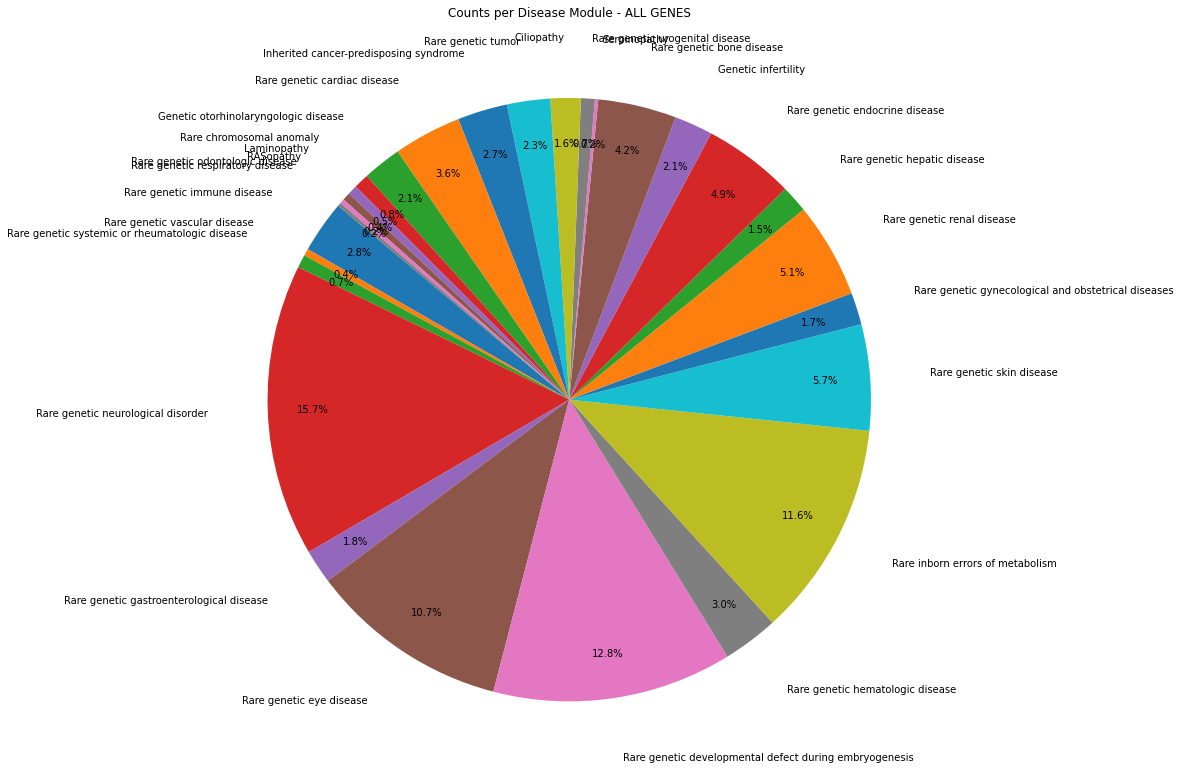

In [54]:
import matplotlib.pyplot as plt

# Pie chart for counts per module using disease_modules_count_dict
labels = list(disease_modules_count_dict.keys())
sizes = list(disease_modules_count_dict.values())

plt.figure(figsize=(16, 16))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, labeldistance=1.2, pctdistance=0.85)
plt.title('Counts per Disease Module - ALL GENES')
plt.tight_layout()
plt.show()